<a href="https://colab.research.google.com/github/Hashirq46/Flower_Classification/blob/main/notebooks/flower_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Check Google Colab Environment

import sys
import os

print("Python Version:", sys.version)
print("Working Directory:", os.getcwd())

# Check GPU
!nvidia-smi

Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Working Directory: /content
Wed Nov 25 10:27:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |  

In [2]:

!pip install -q kagglehub


In [3]:

import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "alxmamaev/flowers-recognition"
)

print("Dataset downloaded successfully!")
print("Dataset path:", dataset_path)


Using Colab cache for faster access to the 'flowers-recognition' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/flowers-recognition


In [4]:

from pathlib import Path

for folder in Path(dataset_path).rglob("*"):
    if folder.is_dir():
        images = list(folder.glob("*.jpg"))
        if images:
            print(folder.name, ":", len(images), "images")


dandelion : 1052 images
daisy : 764 images
sunflower : 733 images
tulip : 984 images
rose : 784 images


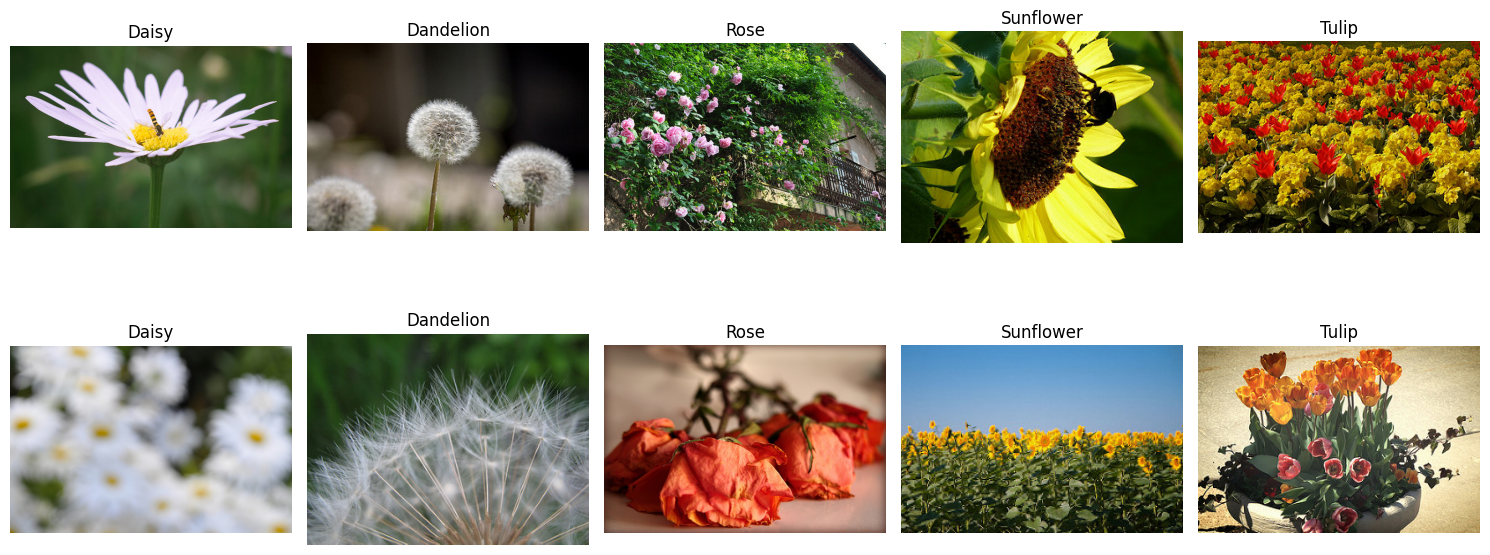

In [6]:

import matplotlib.pyplot as plt
import random
from pathlib import Path
from PIL import Image

categories = ["daisy", "dandelion", "rose", "sunflower", "tulip"]

# Supported image formats
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row in range(2):
    for col, category in enumerate(categories):

        # Search recursively for images
        folder = Path(dataset_path)

        images = [
            p for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in extensions
            and category.lower() in p.parts
        ]

        if not images:
            print(f"No images found for {category}")
            continue

        image_path = random.choice(images)
        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(category.capitalize())
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [7]:

from collections import Counter

image_sizes = Counter()

for category in categories:

    images = [
        p for p in Path(dataset_path).rglob("*")
        if p.is_file()
        and p.suffix.lower() in extensions
        and category.lower() in p.parts
    ]

    for image_path in images:
        with Image.open(image_path) as img:
            image_sizes[img.size] += 1

print("Image dimensions:")
for size, count in image_sizes.most_common(10):
    print(size, ":", count)


Image dimensions:
(320, 240) : 604
(500, 333) : 599
(240, 159) : 378
(320, 213) : 322
(240, 240) : 219
(180, 240) : 154
(159, 240) : 141
(500, 375) : 124
(500, 332) : 118
(240, 180) : 69


In [8]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [9]:

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

class_names = train_dataset.class_names

print("Flower categories:", class_names)


Found 4317 files belonging to 1 classes.
Using 3454 files for training.
Found 4317 files belonging to 1 classes.
Using 863 files for validation.
Flower categories: ['flowers']


In [10]:

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

print("Dataset preparation completed!")


Dataset preparation completed!


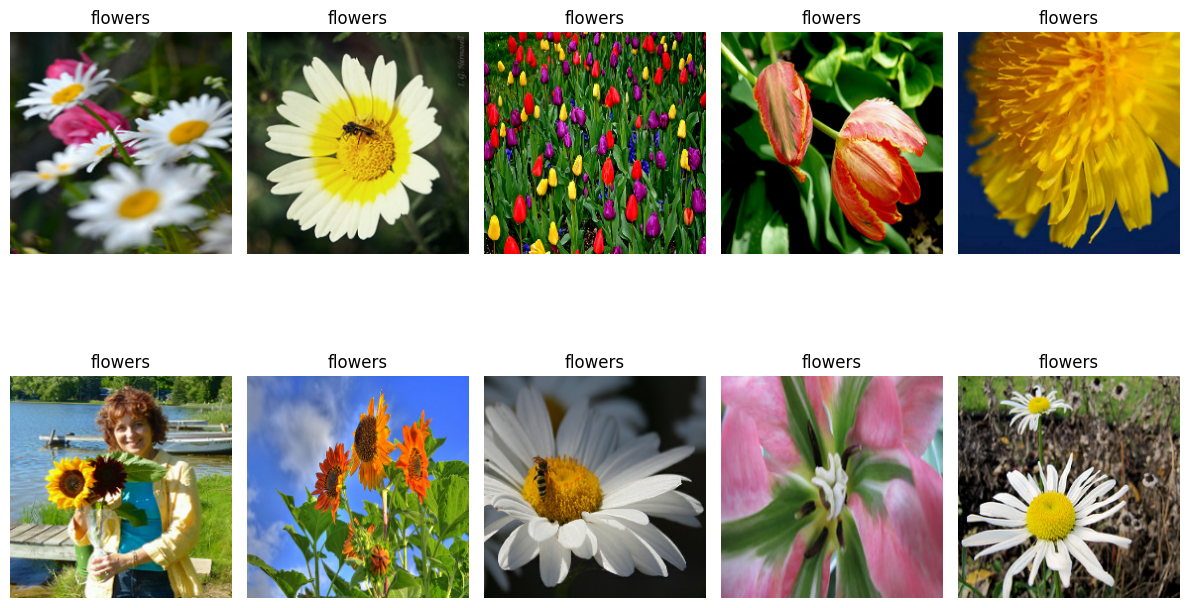

In [11]:

plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):
    for i in range(10):
        plt.subplot(2, 5, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_index = np.argmax(labels[i].numpy())

        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [12]:

from pathlib import Path

categories = ["daisy", "dandelion", "rose", "sunflower", "tulip"]

# Find the directory containing all five category folders
dataset_root = None

for folder in Path(dataset_path).rglob("*"):
    if folder.is_dir():
        subfolders = {
            p.name.lower() for p in folder.iterdir() if p.is_dir()
        }

        if set(categories).issubset(subfolders):
            dataset_root = folder
            break

print("Correct dataset directory:", dataset_root)
print("Available categories:",
      [p.name for p in dataset_root.iterdir() if p.is_dir()])


Correct dataset directory: /kaggle/input/flowers-recognition/flowers
Available categories: ['dandelion', 'daisy', 'sunflower', 'tulip', 'rose']


In [13]:

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_root,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_root,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

class_names = train_dataset.class_names

print("Flower classes:", class_names)
print("Number of classes:", len(class_names))


Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Flower classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Number of classes: 5


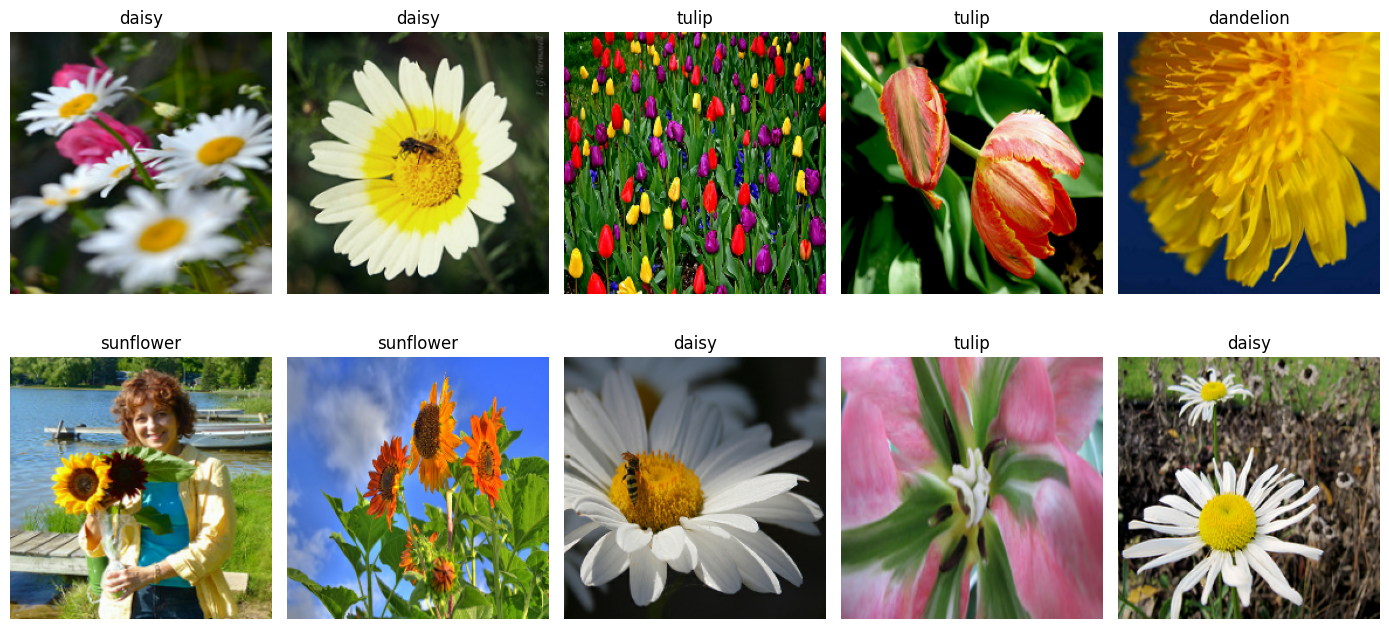

In [14]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 7))

for images, labels in train_dataset.take(1):
    for i in range(10):
        plt.subplot(2, 5, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_index = np.argmax(labels[i].numpy())

        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [15]:

from tensorflow.keras import layers, models

num_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Normalize pixel values
    layers.Rescaling(1./255),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Classification layers
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),

    # Five flower categories
    layers.Dense(num_classes, activation='softmax')
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,245,957 (84.86 MB)

 Trainable params: 22,245,957 (84.86 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


In [17]:

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15
)


Epoch 1/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 37s 223ms/step - accuracy: 0.4074 - loss: 1.4649 - val_accuracy: 0.4936 - val_loss: 1.1558
Epoch 2/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 8s 73ms/step - accuracy: 0.5507 - loss: 1.1306 - val_accuracy: 0.5435 - val_loss: 1.0785
Epoch 3/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.6045 - loss: 1.0017 - val_accuracy: 0.5817 - val_loss: 0.9560
Epoch 4/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 8s 75ms/step - accuracy: 0.6659 - loss: 0.8763 - val_accuracy: 0.6246 - val_loss: 0.9072
Epoch 5/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 0.7360 - loss: 0.7089 - val_accuracy: 0.6477 - val_loss: 0.8931
Epoch 6/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - accuracy: 0.8040 - loss: 0.5275 - val_accuracy: 0.6512 - val_loss: 0.9339
Epoch 7/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.8723 - loss: 0.3620 - val_accuracy: 0.6524 - val_loss: 1.0762
Epoch 8/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.9056 - loss: 0.2753 - val_a

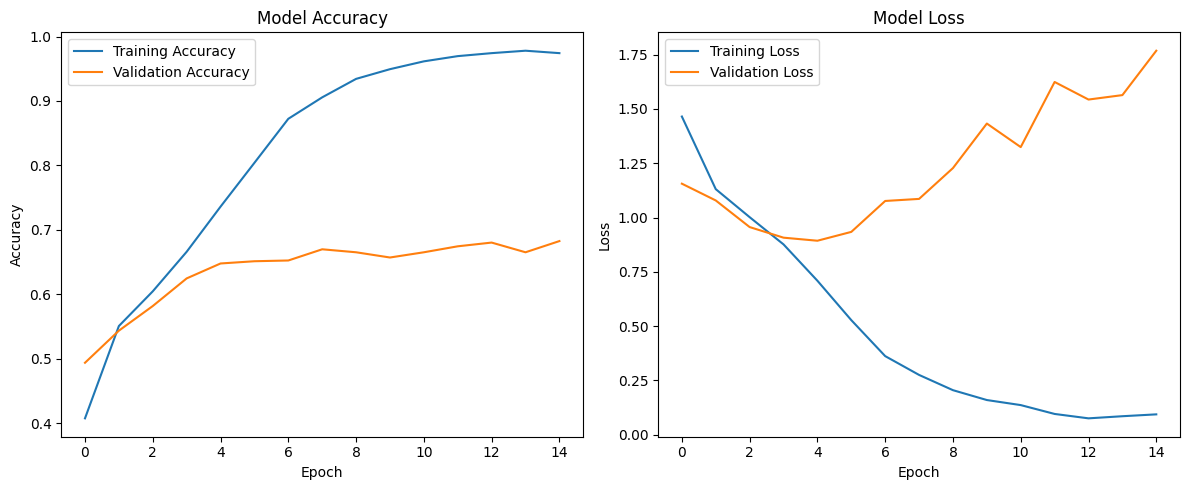

In [18]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [19]:

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1)
])

print("Data augmentation created!")


Data augmentation created!


In [20]:

improved_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    layers.Rescaling(1./255),

    # Block 1
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    # Block 2
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    # Block 3
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    # Block 4
    layers.Conv2D(256, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    # Classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.5),

    layers.Dense(num_classes, activation='softmax')
])

improved_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,877 (1.62 MB)

 Trainable params: 422,917 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [21]:

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Improved CNN compiled successfully!")


Improved CNN compiled successfully!


In [22]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=0.00001
    ),

    tf.keras.callbacks.ModelCheckpoint(
        '/content/best_flower_cnn.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

improved_history = improved_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=25,
    callbacks=callbacks
)


Epoch 1/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 28s 160ms/step - accuracy: 0.4658 - loss: 1.5300 - val_accuracy: 0.2387 - val_loss: 2.4563 - learning_rate: 0.0010
Epoch 2/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 16s 145ms/step - accuracy: 0.5455 - loss: 1.2944 - val_accuracy: 0.2387 - val_loss: 2.5128 - learning_rate: 0.0010
Epoch 3/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 15s 136ms/step - accuracy: 0.5880 - loss: 1.2152 - val_accuracy: 0.2735 - val_loss: 1.9577 - learning_rate: 0.0010
Epoch 4/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 15s 135ms/step - accuracy: 0.6288 - loss: 1.1275 - val_accuracy: 0.2735 - val_loss: 2.0620 - learning_rate: 0.0010
Epoch 5/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 16s 148ms/step - accuracy: 0.6410 - loss: 1.0681 - val_accuracy: 0.5527 - val_loss: 1.2191 - learning_rate: 0.0010
Epoch 6/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 15s 136ms/step - accuracy: 0.6561 - loss: 1.0406 - val_accuracy: 0.5713 - val_loss: 1.2870 - learning_rate: 0.0010
Epoch 7/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 15s 137ms/step - accuracy: 0.6

In [23]:

best_model = tf.keras.models.load_model(
    '/content/best_flower_cnn.keras'
)

print("Best checkpoint loaded successfully!")


Best checkpoint loaded successfully!


In [24]:

import numpy as np

y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = best_model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total validation predictions:", len(y_pred))


Total validation predictions: 863


In [25]:

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

       daisy       0.85      0.73      0.79       144
   dandelion       0.83      0.83      0.83       206
        rose       0.65      0.61      0.63       137
   sunflower       0.87      0.91      0.89       172
       tulip       0.70      0.78      0.74       204

    accuracy                           0.78       863
   macro avg       0.78      0.77      0.77       863
weighted avg       0.78      0.78      0.78       863



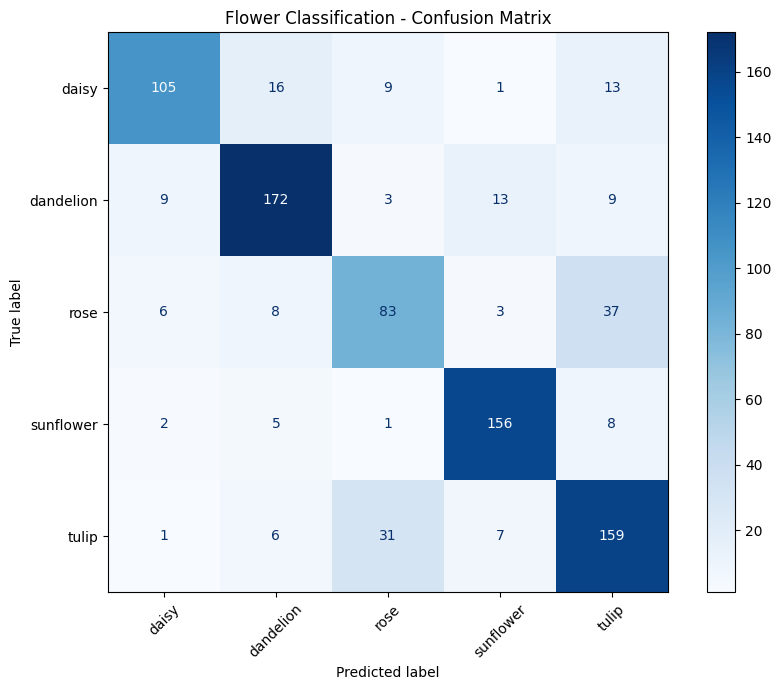

In [26]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45,
    values_format='d'
)

plt.title("Flower Classification - Confusion Matrix")
plt.tight_layout()
plt.show()


In [27]:

import tensorflow as tf
from tensorflow.keras import layers, models

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze pretrained layers initially
base_model.trainable = False

print("MobileNetV2 loaded successfully!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [28]:

inputs = layers.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Extract pretrained features
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation='softmax'
)(x)

mobilenet_model = models.Model(inputs, outputs)

mobilenet_model.summary()


Model: "functional_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [29]:

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("MobileNetV2 compiled successfully!")


MobileNetV2 compiled successfully!


In [30]:

mobilenet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        '/content/best_mobilenet_flowers.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        patience=2,
        factor=0.5,
        min_lr=0.00001
    )
]

mobilenet_history = mobilenet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=mobilenet_callbacks
)


Epoch 1/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 19s 118ms/step - accuracy: 0.7163 - loss: 0.7891 - val_accuracy: 0.8459 - val_loss: 0.4467 - learning_rate: 0.0010
Epoch 2/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 10s 90ms/step - accuracy: 0.8188 - loss: 0.5028 - val_accuracy: 0.8552 - val_loss: 0.4196 - learning_rate: 0.0010
Epoch 3/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 10s 86ms/step - accuracy: 0.8338 - loss: 0.4475 - val_accuracy: 0.8679 - val_loss: 0.3598 - learning_rate: 0.0010
Epoch 4/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 9s 81ms/step - accuracy: 0.8558 - loss: 0.3861 - val_accuracy: 0.8598 - val_loss: 0.3741 - learning_rate: 0.0010
Epoch 5/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.8622 - loss: 0.3652 - val_accuracy: 0.8679 - val_loss: 0.3601 - learning_rate: 0.0010
Epoch 6/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 11s 105ms/step - accuracy: 0.8827 - loss: 0.3250 - val_accuracy: 0.8818 - val_loss: 0.3296 - learning_rate: 5.0000e-04
Epoch 7/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - accuracy: 0.8911

In [31]:

mobilenet_model = tf.keras.models.load_model(
    '/content/best_mobilenet_flowers.keras'
)

print("Best MobileNetV2 checkpoint loaded!")


Best MobileNetV2 checkpoint loaded!


In [32]:

# Access pretrained MobileNetV2 base
base_model = mobilenet_model.get_layer("mobilenetv2_1.00_224")

# Enable fine-tuning
base_model.trainable = True

# Freeze earlier layers and train only the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Total layers:", len(base_model.layers))
print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))


Total layers: 154
Trainable layers: 19


In [33]:

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning model compiled!")


Fine-tuning model compiled!


In [34]:

fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        '/content/final_flower_model.keras',
        monitor='val_loss',
        save_best_only=True
    )
]

fine_tune_history = mobilenet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=fine_tune_callbacks
)


Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - accuracy: 0.9079 - loss: 0.2513 - val_accuracy: 0.8899 - val_loss: 0.3023
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.9076 - loss: 0.2396 - val_accuracy: 0.9027 - val_loss: 0.2807
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 9s 84ms/step - accuracy: 0.9253 - loss: 0.2064 - val_accuracy: 0.9015 - val_loss: 0.2877
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 11s 97ms/step - accuracy: 0.9239 - loss: 0.2070 - val_accuracy: 0.9073 - val_loss: 0.2517
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 9s 87ms/step - accuracy: 0.9337 - loss: 0.1824 - val_accuracy: 0.9131 - val_loss: 0.2722
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 9s 84ms/step - accuracy: 0.9282 - loss: 0.1936 - val_accuracy: 0.9131 - val_loss: 0.2592
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 9s 87ms/step - accuracy: 0.9282 - loss: 0.1906 - val_accuracy: 0.9085 - val_loss: 0.2535


In [35]:

print("Epochs completed:",
      len(fine_tune_history.history['accuracy']))

print("Best validation accuracy:",
      round(max(fine_tune_history.history['val_accuracy']) * 100, 2), "%")

print("Best validation loss:",
      round(min(fine_tune_history.history['val_loss']), 4))

print("Best epoch:",
      np.argmin(fine_tune_history.history['val_loss']) + 1)


Epochs completed: 7
Best validation accuracy: 91.31 %
Best validation loss: 0.2517
Best epoch: 4


In [36]:

final_model = tf.keras.models.load_model(
    '/content/final_flower_model.keras'
)

print("Final model loaded successfully!")


Final model loaded successfully!


In [37]:

from sklearn.metrics import classification_report
import numpy as np

y_true_final = []
y_pred_final = []

for images, labels in validation_dataset:

    predictions = final_model.predict(images, verbose=0)

    y_true_final.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    y_pred_final.extend(
        np.argmax(predictions, axis=1)
    )

print(classification_report(
    y_true_final,
    y_pred_final,
    target_names=class_names
))


              precision    recall  f1-score   support

       daisy       0.88      0.90      0.89       144
   dandelion       0.94      0.90      0.92       206
        rose       0.87      0.90      0.88       137
   sunflower       0.90      0.93      0.92       172
       tulip       0.92      0.91      0.92       204

    accuracy                           0.91       863
   macro avg       0.90      0.91      0.91       863
weighted avg       0.91      0.91      0.91       863



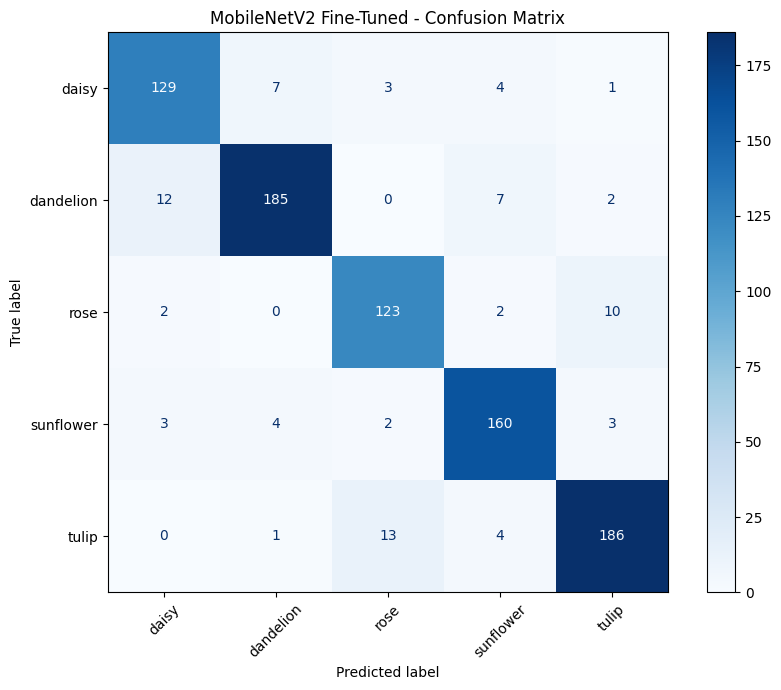

In [38]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_final = confusion_matrix(
    y_true_final,
    y_pred_final
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)

plt.title("MobileNetV2 Fine-Tuned - Confusion Matrix")
plt.tight_layout()
plt.show()


In [39]:

import os
from pathlib import Path

# Common image extensions
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

root = Path('/content')

print("DATASET STRUCTURE")
print("=" * 50)

for current_path, dirs, files in os.walk(root):
    current = Path(current_path)

    # Avoid unnecessary system directories
    dirs[:] = [d for d in dirs if d not in {
        '.config', '.cache', '__pycache__'
    }]

    depth = len(current.relative_to(root).parts)

    if depth > 4:
        dirs[:] = []
        continue

    images = [
        f for f in files
        if Path(f).suffix.lower() in image_extensions
    ]

    if images:
        print(f"{current}: {len(images)} images")

print("\nCURRENT DATASET VARIABLES")
print("=" * 50)

for name in ['train_dataset', 'validation_dataset',
             'class_names', 'train_dir', 'data_dir']:
    if name in globals():
        print(name, "=", globals()[name])
    else:
        print(name, "= Not found")


DATASET STRUCTURE

CURRENT DATASET VARIABLES
train_dataset = <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))>
validation_dataset = <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))>
class_names = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
train_dir = Not found
data_dir = Not found


In [40]:

import os
from pathlib import Path

search_locations = [
    Path('/content'),
    Path('/kaggle/input'),
    Path('/root/.cache/kagglehub'),
    Path('/content/drive/MyDrive')
]

print("SEARCHING FOR FLOWER DATASET")
print("=" * 50)

for location in search_locations:

    if not location.exists():
        print(f"\nNot available: {location}")
        continue

    print(f"\nSearching: {location}")

    found = 0

    for current, dirs, files in os.walk(location):
        dirs[:] = [
            d for d in dirs
            if d not in ['.config', '.cache', '__pycache__']
        ]

        folder_names = {d.lower() for d in dirs}

        required = {
            'daisy', 'dandelion', 'rose',
            'sunflower', 'tulip'
        }

        if required.issubset(folder_names):
            print("POSSIBLE FLOWER DATASET FOUND:")
            print(current)
            found += 1

        if found >= 10:
            break

    if found == 0:
        print("No matching dataset folder found.")

SEARCHING FOR FLOWER DATASET

Searching: /content
No matching dataset folder found.

Searching: /kaggle/input
POSSIBLE FLOWER DATASET FOUND:
/kaggle/input/flowers-recognition/flowers

Not available: /root/.cache/kagglehub

Not available: /content/drive/MyDrive


In [41]:

print("TRAINING DATA")
print("Images:", tf.data.experimental.cardinality(
    train_dataset
).numpy())

print("\nVALIDATION DATA")
print("Batches:", tf.data.experimental.cardinality(
    validation_dataset
).numpy())

print("\nCLASS NAMES:", class_names)

TRAINING DATA
Images: 108

VALIDATION DATA
Batches: 27

CLASS NAMES: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [42]:

from pathlib import Path

dataset_path = Path('/kaggle/input/flowers-recognition/flowers')

total_images = 0

print("ORIGINAL KAGGLE DATASET")
print("-" * 45)

for class_name in class_names:
    folder = dataset_path / class_name

    images = [
        f for f in folder.iterdir()
        if f.suffix.lower() in ['.jpg', '.jpeg', '.png']
    ]

    print(f"{class_name}: {len(images)} images")
    total_images += len(images)

print("-" * 45)
print("TOTAL IMAGES:", total_images)


ORIGINAL KAGGLE DATASET
---------------------------------------------
daisy: 764 images
dandelion: 1052 images
rose: 784 images
sunflower: 733 images
tulip: 984 images
---------------------------------------------
TOTAL IMAGES: 4317


In [43]:

import os
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split

# Original Kaggle dataset
source_dir = Path('/kaggle/input/flowers-recognition/flowers')

# New dataset location
output_dir = Path('/content/flower_split')

classes = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']

# Reproducible random splitting
SEED = 42

# Supported image formats
extensions = {'.jpg', '.jpeg', '.png'}

# Create dataset folders
for split in ['train', 'validation', 'test']:
    for class_name in classes:
        (output_dir / split / class_name).mkdir(
            parents=True, exist_ok=True
        )

# Split and copy images
for class_name in classes:

    folder = source_dir / class_name

    images = [
        p for p in folder.iterdir()
        if p.suffix.lower() in extensions
    ]

    # 70% training, 30% remaining
    train_images, remaining_images = train_test_split(
        images,
        test_size=0.30,
        random_state=SEED,
        shuffle=True
    )

    # Divide remaining 30% equally
    val_images, test_images = train_test_split(
        remaining_images,
        test_size=0.50,
        random_state=SEED,
        shuffle=True
    )

    # Copy images into their respective folders
    for image in train_images:
        shutil.copy2(
            image,
            output_dir / 'train' / class_name / image.name
        )

    for image in val_images:
        shutil.copy2(
            image,
            output_dir / 'validation' / class_name / image.name
        )

    for image in test_images:
        shutil.copy2(
            image,
            output_dir / 'test' / class_name / image.name
        )

    print(
        f"{class_name}: "
        f"Train={len(train_images)}, "
        f"Validation={len(val_images)}, "
        f"Test={len(test_images)}"
    )

print("\nDataset splitting completed!")
print("Dataset location:", output_dir)


daisy: Train=534, Validation=115, Test=115
dandelion: Train=736, Validation=158, Test=158
rose: Train=548, Validation=118, Test=118
sunflower: Train=513, Validation=110, Test=110
tulip: Train=688, Validation=148, Test=148

Dataset splitting completed!
Dataset location: /content/flower_split


In [44]:

for split in ['train', 'validation', 'test']:

    print(f"\n{split.upper()} DATASET")
    print("-" * 35)

    total = 0

    for class_name in classes:

        folder = output_dir / split / class_name

        count = len([
            p for p in folder.iterdir()
            if p.suffix.lower() in extensions
        ])

        total += count

        print(f"{class_name}: {count}")

    print("TOTAL:", total)



TRAIN DATASET
-----------------------------------
daisy: 534
dandelion: 736
rose: 548
sunflower: 513
tulip: 688
TOTAL: 3019

VALIDATION DATASET
-----------------------------------
daisy: 115
dandelion: 158
rose: 118
sunflower: 110
tulip: 148
TOTAL: 649

TEST DATASET
-----------------------------------
daisy: 115
dandelion: 158
rose: 118
sunflower: 110
tulip: 148
TOTAL: 649


In [45]:

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    output_dir / 'train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    class_names=classes,
    shuffle=True,
    seed=42
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    output_dir / 'validation',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    class_names=classes,
    shuffle=False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    output_dir / 'test',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    class_names=classes,
    shuffle=False
)

print("\nAll three datasets loaded successfully!")
print("Classes:", train_dataset.class_names)


Found 3019 files belonging to 5 classes.
Found 649 files belonging to 5 classes.
Found 649 files belonging to 5 classes.

All three datasets loaded successfully!
Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [46]:

import tensorflow as tf
from tensorflow.keras import layers, models

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)
validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1)
])

print("Data augmentation and prefetching ready!")


Data augmentation and prefetching ready!


In [47]:

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

print("Pretrained MobileNetV2 loaded!")

Pretrained MobileNetV2 loaded!


In [48]:

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(5, activation='softmax')(x)

new_model = models.Model(inputs, outputs)

new_model.summary()

Model: "functional_35"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [49]:

new_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("New model compiled successfully!")

New model compiled successfully!


In [50]:

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '/content/fresh_mobilenet_best.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        patience=2,
        factor=0.5,
        min_lr=0.00001
    )
]

initial_history = new_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5765 - loss: 1.1261
Epoch 1: val_loss improved from None to 0.41839, saving model to /content/fresh_mobilenet_best.keras

Epoch 1: finished saving model to /content/fresh_mobilenet_best.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 17s 118ms/step - accuracy: 0.6956 - loss: 0.8176 - val_accuracy: 0.8552 - val_loss: 0.4184 - learning_rate: 0.0010
Epoch 2/15
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.8157 - loss: 0.5055
Epoch 2: val_loss improved from 0.41839 to 0.35440, saving model to /content/fresh_mobilenet_best.keras

Epoch 2: finished saving model to /content/fresh_mobilenet_best.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.8218 - loss: 0.4909 - val_accuracy: 0.8798 - val_loss: 0.3544 - learning_rate: 0.0010
Epoch 3/15
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.8440 - loss: 0.4483
Epoch 3: val_loss improved from 0.35440 to 0.34195, saving model to /content/fresh_mobilenet_best.keras

Epoch 3: fi

In [51]:

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))

Trainable layers: 19


In [52]:

new_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning compilation completed!")

Fine-tuning compilation completed!


In [53]:


fine_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '/content/final_flower_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )
]

fine_history = new_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=fine_callbacks
)

Epoch 1/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.9146 - loss: 0.2302
Epoch 1: val_loss improved from None to 0.27517, saving model to /content/final_flower_model.keras

Epoch 1: finished saving model to /content/final_flower_model.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - accuracy: 0.9132 - loss: 0.2306 - val_accuracy: 0.9137 - val_loss: 0.2752
Epoch 2/10
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.9216 - loss: 0.2276
Epoch 2: val_loss improved from 0.27517 to 0.26930, saving model to /content/final_flower_model.keras

Epoch 2: finished saving model to /content/final_flower_model.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 9s 97ms/step - accuracy: 0.9198 - loss: 0.2228 - val_accuracy: 0.9106 - val_loss: 0.2693
Epoch 3/10
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.9199 - loss: 0.2171
Epoch 3: val_loss did not improve from 0.26930
95/95 ━━━━━━━━━━━━━━━━━━━━ 9s 99ms/step - accuracy: 0.9159 - loss: 0.2232 - val_accuracy: 0.9060 - val_loss: 0.2694
Epoch 4/1

In [54]:
# Load the best saved model
final_model = tf.keras.models.load_model(
    "/content/final_flower_model.keras"
)

# Evaluate on test dataset
test_loss, test_accuracy = final_model.evaluate(test_dataset)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - accuracy: 0.8983 - loss: 0.2764
Test Accuracy: 89.83%
Test Loss: 0.2764


21/21 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step


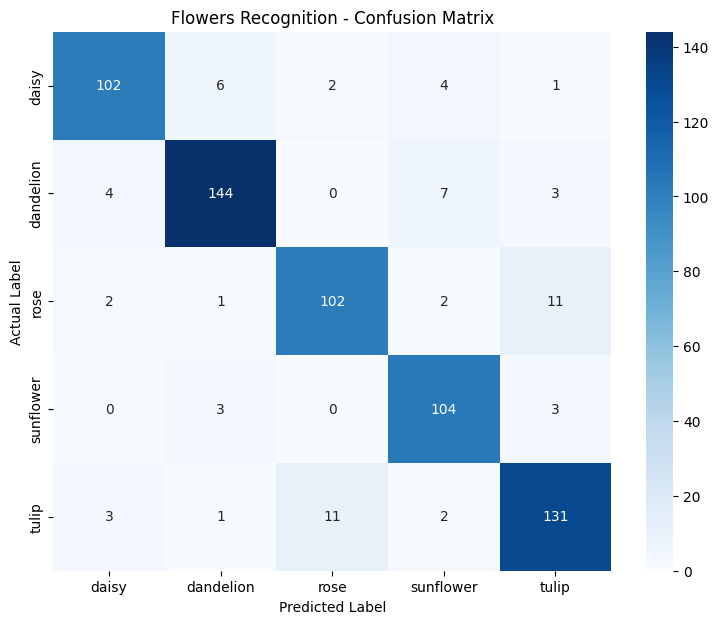

              precision    recall  f1-score   support

       daisy       0.92      0.89      0.90       115
   dandelion       0.93      0.91      0.92       158
        rose       0.89      0.86      0.88       118
   sunflower       0.87      0.95      0.91       110
       tulip       0.88      0.89      0.88       148

    accuracy                           0.90       649
   macro avg       0.90      0.90      0.90       649
weighted avg       0.90      0.90      0.90       649



In [55]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Get actual labels
y_true = np.concatenate([
    labels.numpy().argmax(axis=1)
    for images, labels in test_dataset
])

# Get predictions
y_pred = np.argmax(
    final_model.predict(test_dataset),
    axis=1
)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Flowers Recognition - Confusion Matrix")
plt.show()

# Classification Report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

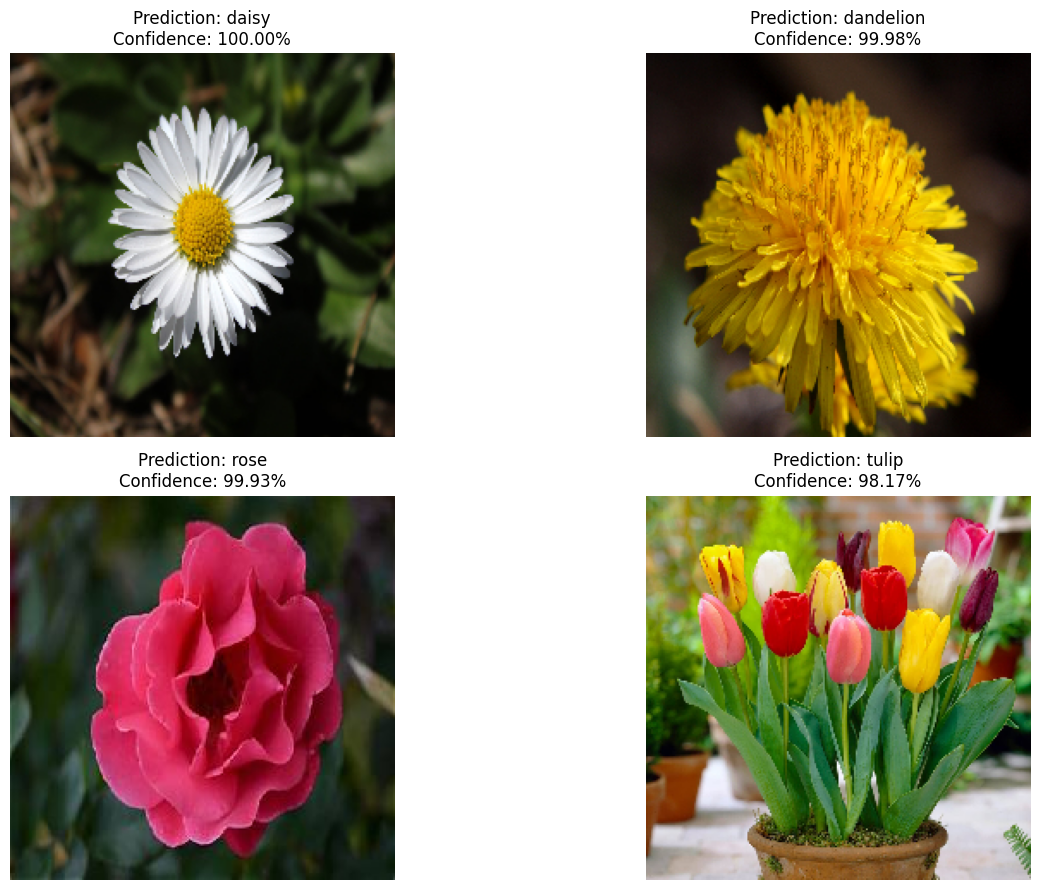

In [56]:

import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Load your trained model
final_model = tf.keras.models.load_model(
    "/content/final_flower_model.keras"
)

# Test images
image_files = [
    "/content/f1.jpg",
    "/content/f2.jpg",
    "/content/f3.jpg",
    "/content/f5.jpg"
]

plt.figure(figsize=(15, 9))

for i, img_path in enumerate(image_files):

    # Load and preprocess image
    img = image.load_img(
        img_path,
        target_size=(224, 224)
    )

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    predictions = final_model.predict(
        img_array, verbose=0
    )

    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    # Display
    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [57]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [58]:
import os
import shutil

# Create project backup folder
backup_path = "/content/drive/MyDrive/Flowers_Recognition_Backup"
os.makedirs(backup_path, exist_ok=True)

# Copy trained model
shutil.copy(
    "/content/final_flower_model.keras",
    backup_path
)

print("Model successfully backed up!")
print("Location:", backup_path)

Model successfully backed up!
Location: /content/drive/MyDrive/Flowers_Recognition_Backup


In [59]:
import os

model_path = "/content/final_flower_model.keras"

size_mb = os.path.getsize(model_path) / (1024 * 1024)

print(f"Model size: {size_mb:.2f} MB")

Model size: 22.61 MB
